Для выполнения лабораторной работы выбирал модель Random Forest. Данный алгоритм имеет три значимых гиперпараметра: n_estimators (целочисленный), max_depth (целочисленный) и min_samples_leaf (целочисленный), что позволяет наглядно продемонстрировать зависимость качества от сложности модели, увидеть зоны недообучения и переобучения. Параметры не требуют логарифмического масштабирования, как для SVM. Кроме того, Random Forest обычно показывает высокий F1-score на Titanic, и его оптимизация даст заметный прирост по сравнению с дефолтными настройками.

In [1]:
import numpy as np
import pandas as pd
import time
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5
N_ITER = 48
BASELINE_N_ESTIMATORS = 200

df = pd.read_csv('Titanic-Dataset.csv')

cat_cols = ['Sex', 'Embarked']
num_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
drop_cols = ['PassengerId', 'Name', 'Ticket', 'Cabin']

In [2]:
X = df.drop(columns=['Survived'] + drop_cols)
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(drop='first', sparse_output=False))
        ]), cat_cols)
    ]
)

baseline_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(n_estimators=BASELINE_N_ESTIMATORS, random_state=RANDOM_STATE))
])

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_results = cross_validate(
    baseline_pipe, X_train, y_train, cv=cv,
    scoring='f1', n_jobs=-1, return_train_score=False
)
fold_scores = cv_results['test_score']

baseline_pipe.fit(X_train, y_train)
y_pred = baseline_pipe.predict(X_test)
test_f1 = f1_score(y_test, y_pred)

print('Baseline Random Forest:')
print(f'n_estimators={BASELINE_N_ESTIMATORS}, random_state={RANDOM_STATE}')
print(f'остальные параметры по умолчанию')
print(f'\nF1 по фолдам (5-fold CV):')
for i, score in enumerate(fold_scores, start=1):
    print(f'  fold {i}: {score:.4f}')
print(f'\nCV F1 mean: {fold_scores.mean():.4f}')
print(f'CV F1 std:  {fold_scores.std():.4f}')
print(f'\nTest F1: {test_f1:.4f}')

Baseline Random Forest:
n_estimators=200, random_state=42
остальные параметры по умолчанию

F1 по фолдам (5-fold CV):
  fold 1: 0.7455
  fold 2: 0.7339
  fold 3: 0.7593
  fold 4: 0.7080
  fold 5: 0.7327

CV F1 mean: 0.7359
CV F1 std:  0.0169

Test F1: 0.7576


In [3]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

print('Доля класса 1 (выжившие) по validation-фолдам:')
for fold_idx, (_, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    share = y_train.iloc[val_idx].mean()
    print(f'  fold {fold_idx}: share={share:.3f}, n_val={len(val_idx)}')

Доля класса 1 (выжившие) по validation-фолдам:
  fold 1: share=0.385, n_val=143
  fold 2: share=0.385, n_val=143
  fold 3: share=0.387, n_val=142
  fold 4: share=0.380, n_val=142
  fold 5: share=0.380, n_val=142


Пространство поиска - 48 комбинаций, это 240 обучений модели при 5-fold CV.

Для кросс-валидации выбрано 5 фолдов StratifiedKFold с shuffle=True и фиксированным random_state. 5 фолдов дают 80% train и 20% validation на каждом фолде, достаточный компромисс для стабильной оценки F1 на валидации и не слишком дорогого обучения. Большее количество фолдов создает слишком малые validation-наборы, из-за чего растет дисперсия и шумность предсказаний, при меньшем количестве фолдов будем получать более пессимистичную оценку ввиду меньшего объема train-выборки. StratifiedKFold сохраняет долю классов в каждом фолде, что критично для Titanic с его дисбалансом примерно 62% / 38%.

Кросс-валидация нужна потому, что одно разбиение train/validation даёт оценку, зависящую от конкретного случайного разбиения. Если в validation попали лёгкие или трудные объекты, оценка смещается вверх или вниз. Кросс-валидация усредняет качество по нескольким разбиениям, даёт более робастную оценку обобщающей способности и позволяет увидеть разброс между фолдами. Одного разбиения train/test для подбора параметров недостаточно по той же причине.

Если многократно выбирать гиперпараметры по результату на test, test перестаёт быть независимым. Каждый раз, глядя на test F1 и меняя параметры, мы неявно используем информацию из test для выбора модели, и финальная оценка становится оптимистичной. На новых данных реальное качество будет ниже.


In [4]:
param_grid = {
    'model__n_estimators': [100, 200, 300, 450],
    'model__max_depth': [4, 6, 8, None],
    'model__min_samples_leaf': [1, 2, 5],
}

Для Random Forest выбраны три значимых гиперпараметра. 

n_estimators - количество деревьев в ансамбле. Каждое дерево обучается на bootstrap-выборке со случайным подмножеством признаков, а итоговое предсказание получается усреднением. Разумный диапазон - [100, 200, 300, 500]. С ростом числа деревьев предсказания становятся стабильнее, дисперсия ансамбля падает, качество на валидации растёт. После определённого количества деревьев прирост замедлится, а время обучения вырастет линейно. Кроме того, n_estimators не исправит систематическую ошибку от слишком глубоких или слишком мелких деревьев, поэтому он работает в связке с max_depth и min_samples_leaf.

max_depth - максимальная глубина каждого дерева в ансамбле. None означает отсутствие ограничения, дерево растёт до исчерпания или до min_samples_split. Разумный диапазон - [4, 6, 8, None]. При маленькой глубине ансамбль недообучается: деревья слишком простые и не улавливают нелинейные зависимости. При большой глубине или None каждое дерево может переобучиться, но усреднение по 100-500 деревьям сгладит переобучение и частично возвратит обобщающую способность.

min_samples_leaf - минимальное количество объектов в листе. Если после разбиения лист содержал бы меньше объектов, разбиение не производится, и узел становится листом. Это регуляризатор, который запрещает вырожденные листья под отдельные объекты. Разумный диапазон - [1, 2, 5]. Значение 1 разрешает листья из одного объекта, каждое дерево может идеально запомнить train, ансамбль сглаживает, но остаётся склонность к переобучению. Значение 5 заставляет листья быть крупными, что сглаживает разбиения и может улучшить обобщение, но при слишком большом значении приводит к недообучению. 

Проводим поиск по заранее заданной сетке GridSearchCV. Сетка содержит 3 параметра: n_estimators - [100, 200, 300, 500], max_depth - [4, 6, 8, None], min_samples_leaf - [1, 2, 5]. Итого 48 комбинаций, что при 5-fold CV даёт 240 обучений модели.

In [5]:
grid_search = GridSearchCV(
    estimator=baseline_pipe,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False
)

start_time = time.perf_counter()
grid_search.fit(X_train, y_train)
grid_time = time.perf_counter() - start_time

grid_results = pd.DataFrame(grid_search.cv_results_)

best_idx = grid_search.best_index_
best_row = grid_results.loc[best_idx]

print('GridSearchCV:')
print(f'Пространство поиска: {N_ITER} комбинаций')
print(f'Обучений модели: {N_ITER * N_SPLITS}')
print(f'\nВремя выполнения Grid Search: {grid_time:.2f} сек')
print(f'\nЛучший набор гиперпараметров: {grid_search.best_params_}')
print(f'CV F1 (mean): {best_row["mean_test_score"]:.4f}')
print(f'CV F1 (std):  {best_row["std_test_score"]:.4f}')
print(f'\nТоп-5 комбинаций по mean_test_score:')
top5 = grid_results.sort_values('mean_test_score', ascending=False).head(5)
for rank, (_, row) in enumerate(top5.iterrows(), start=1):
    params = {k.replace('model__', ''): v for k, v in row['params'].items()}
    print(f'  {rank}. {params} mean={row["mean_test_score"]:.4f}, std={row["std_test_score"]:.4f}')

GridSearchCV:
Пространство поиска: 48 комбинаций
Обучений модели: 240

Время выполнения Grid Search: 46.98 сек

Лучший набор гиперпараметров: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 450}
CV F1 (mean): 0.7535
CV F1 (std):  0.0280

Топ-5 комбинаций по mean_test_score:
  1. {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 450} mean=0.7535, std=0.0280
  2. {'max_depth': 4, 'min_samples_leaf': 1, 'n_estimators': 300} mean=0.7531, std=0.0373
  3. {'max_depth': 4, 'min_samples_leaf': 5, 'n_estimators': 100} mean=0.7531, std=0.0376
  4. {'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 450} mean=0.7513, std=0.0353
  5. {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200} mean=0.7503, std=0.0297


RandomizedSearchCV не строит полную сетку, а сэмплирует ограниченное число комбинаций из заданных распределений. Бюджет задаётся явно через n_iter: сколько комбинаций проверить, столько и проверим, даже если пространство поиска огромное. Для числовых параметров используются распределения из scipy.stats, а не списки конкретных значений. randint(a, b) даёт случайные целые в полуинтервале [a, b), то есть randint(100, 501) покрывает 100..500 включительно, randint(1, 6) покрывает 1..5. Для параметров с None или категориальными значениями остаётся список, по которому сэмплер случайно выбирает элемент.

In [29]:
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'model__n_estimators': randint(100, 501),
    'model__max_depth': [4, 6, 8, None],
    'model__min_samples_leaf': randint(1, 6),
}

random_search = RandomizedSearchCV(
    estimator=baseline_pipe,
    param_distributions=param_dist,
    n_iter=N_ITER,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    return_train_score=False
)

start_time = time.perf_counter()
random_search.fit(X_train, y_train)
random_time = time.perf_counter() - start_time

random_results = pd.DataFrame(random_search.cv_results_)

best_idx_rs = random_search.best_index_
best_row_rs = random_results.loc[best_idx_rs]

unique_combos = random_results['params'].apply(lambda p: tuple(sorted(p.items()))).nunique()

print('RandomizedSearchCV:')
print(f'n_iter: {N_ITER}')
print(f'Обучений модели: {N_ITER * N_SPLITS}')
print(f'Время выполнения: {random_time:.2f} сек')
print(f'\nЛучший набор: {random_search.best_params_}')
print(f'CV F1 (mean): {best_row_rs["mean_test_score"]:.4f}')
print(f'CV F1 (std):  {best_row_rs["std_test_score"]:.4f}')
print(f'\nТоп-5 комбинаций по mean_test_score:')
top5_rs = random_results.sort_values('mean_test_score', ascending=False).head(5)
for rank, (_, row) in enumerate(top5_rs.iterrows(), start=1):
    params = {k.replace('model__', ''): v for k, v in row['params'].items()}
    print(f'  {rank}. {params} mean={row["mean_test_score"]:.4f}, std={row["std_test_score"]:.4f}')

RandomizedSearchCV:
n_iter: 48
Обучений модели: 240
Время выполнения: 42.43 сек

Лучший набор: {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 388}
CV F1 (mean): 0.7587
CV F1 (std):  0.0374

Топ-5 комбинаций по mean_test_score:
  1. {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 388} mean=0.7587, std=0.0374
  2. {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 463} mean=0.7563, std=0.0391
  3. {'max_depth': 4, 'min_samples_leaf': 4, 'n_estimators': 113} mean=0.7524, std=0.0391
  4. {'max_depth': 4, 'min_samples_leaf': 3, 'n_estimators': 406} mean=0.7512, std=0.0386
  5. {'max_depth': 4, 'min_samples_leaf': 4, 'n_estimators': 235} mean=0.7508, std=0.0406


In [30]:
print(f'\nСравнение Grid vs Random:')
print(f'{"":<20} {"Grid":>10} {"Random":>10}')
print(f'{"Время, сек":<20} {grid_time:>10.2f} {random_time:>10.2f}')
print(f'{"CV F1 mean":<20} {best_row["mean_test_score"]:>10.4f} {best_row_rs["mean_test_score"]:>10.4f}')
print(f'{"CV F1 std":<20} {best_row["std_test_score"]:>10.4f} {best_row_rs["std_test_score"]:>10.4f}')


Сравнение Grid vs Random:
                           Grid     Random
Время, сек                55.13      42.43
CV F1 mean               0.7531     0.7587
CV F1 std                0.0373     0.0374


Random Search при том же бюджете (48 комбинаций, 240 обучений) нашёл комбинацию лучше Grid Search: CV F1 mean 0.7587 против 0.7531 при практически одинаковом (но достаточно большом) std и сопоставимом времени выполнения. Разница в качестве объясняется тем, где именно сетка и сэмплер ищут оптимум. Grid оперировал грубыми списками, а его лучшая комбинация - max_depth=4, min_samples_leaf=1, n_estimators=300 - живёт в зоне мелких деревьев. Random Search использовал randint, то есть проверял в том числе промежуточные значения min_samples_leaf и n_estimators. Его лучшая комбинация - max_depth=None, min_samples_leaf=3, n_estimators=388 - лежит в другой области: глубокие деревья без ограничения по глубине, но с регуляризацией через размер листа.

Случайный поиск покрыл 0.6% пространства и всё равно обошёл полную сетку из 48 вручную подобранных комбинаций. Это подтверждение того, что при фиксированном бюджете ручная сетка "тратит попытки" на одни и те же значения важного параметра, тогда как Random проверяет больше разных значений по каждой оси и чаще попадает в оптимум.

Случайный поиск предпочтительнее полного перебора, когда параметров много и мы не знаем заранее, какие из них важнее, когда часть параметров непрерывна или имеет широкий диапазон, там где шаг +1 бессмыслен, и когда полная сетка становится вычислительно неподъёмной. В нашем случае параметров три и пространство маленькое (8020 точек), поэтому Grid ещё разумен, но уже здесь Random показывает сопоставимое время и лучшее качество. При переходе к моделям с большим кол-вом гиперпараметров разрыв в пользу Random будет только расти.

In [31]:
def sweep_hyperparameter(param_name, values, fixed_params):
    rows = []
    for value in values:
        params = {**fixed_params, param_name: value}
        pipe_sweep = Pipeline([
            ('prep', preprocessor),
            ('model', RandomForestClassifier(random_state=RANDOM_STATE, **params))
        ])
        cv_sweep = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
        cv_res = cross_validate(
            pipe_sweep, X_train, y_train, cv=cv_sweep,
            scoring='f1', n_jobs=-1, return_train_score=True
        )
        rows.append({
            'value': value if value is not None else 'None',
            'train_mean': cv_res['train_score'].mean(),
            'train_std':  cv_res['train_score'].std(),
            'val_mean':   cv_res['test_score'].mean(),
            'val_std':    cv_res['test_score'].std(),
        })
    return pd.DataFrame(rows)

sweep_max_depth = sweep_hyperparameter(
    'max_depth',
    [2, 3, 4, 5, 6, 8, 10, 15, None],
    {'n_estimators': 300, 'min_samples_leaf': 1}
)
sweep_min_leaf = sweep_hyperparameter(
    'min_samples_leaf',
    [1, 2, 3, 5, 10, 20, 30, 50],
    {'n_estimators': 300, 'max_depth': None}
)
sweep_n_est = sweep_hyperparameter(
    'n_estimators',
    [10, 25, 50, 100, 200, 300, 500],
    {'max_depth': None, 'min_samples_leaf': 1}
)

for name, df_sweep in [('max_depth', sweep_max_depth),
                       ('min_samples_leaf', sweep_min_leaf),
                       ('n_estimators', sweep_n_est)]:
    print(f'\n{name}:')
    print(df_sweep.round(4).to_string(index=False))


max_depth:
value  train_mean  train_std  val_mean  val_std
    2      0.7061     0.0132    0.6751   0.0450
    3      0.7726     0.0090    0.7390   0.0301
    4      0.7875     0.0052    0.7531   0.0373
    5      0.8137     0.0124    0.7555   0.0442
    6      0.8376     0.0056    0.7484   0.0341
    8      0.9006     0.0059    0.7382   0.0356
   10      0.9340     0.0065    0.7497   0.0255
   15      0.9736     0.0053    0.7399   0.0157
 None      0.9769     0.0039    0.7433   0.0154

min_samples_leaf:
 value  train_mean  train_std  val_mean  val_std
     1      0.9769     0.0039    0.7433   0.0154
     2      0.8822     0.0045    0.7480   0.0262
     3      0.8571     0.0080    0.7509   0.0434
     5      0.8296     0.0120    0.7349   0.0326
    10      0.7886     0.0066    0.7232   0.0301
    20      0.7428     0.0054    0.7116   0.0284
    30      0.7245     0.0127    0.7079   0.0334
    50      0.6516     0.0183    0.6309   0.0579

n_estimators:
 value  train_mean  train_std  va

Чтобы увидеть зоны недообучения, разумной сложности и переобучения, нужны кривые не только валидации, но и train. Перебираем значения одного гиперпараметра, фиксируя остальные, и на каждом значении считаем F1 на train и на validation через cross_validate с return_train_score=True. Фиксированные точки выбраны так, чтобы обе крайности были видны. Для max_depth база n_estimators=300 и min_samples_leaf=1 - при малой глубине очевидно недообучение, при большой или None каждое дерево переобучается, и это видно по расхождению train и validation. Для min_samples_leaf база n_estimators=300 и max_depth=None - глубокие деревья без ограничения по глубине, так что маленькие листья дают переобучение, а большие - недообучение. Для n_estimators база max_depth=None и min_samples_leaf=1 - показателен именно эффект усреднения по деревьям.

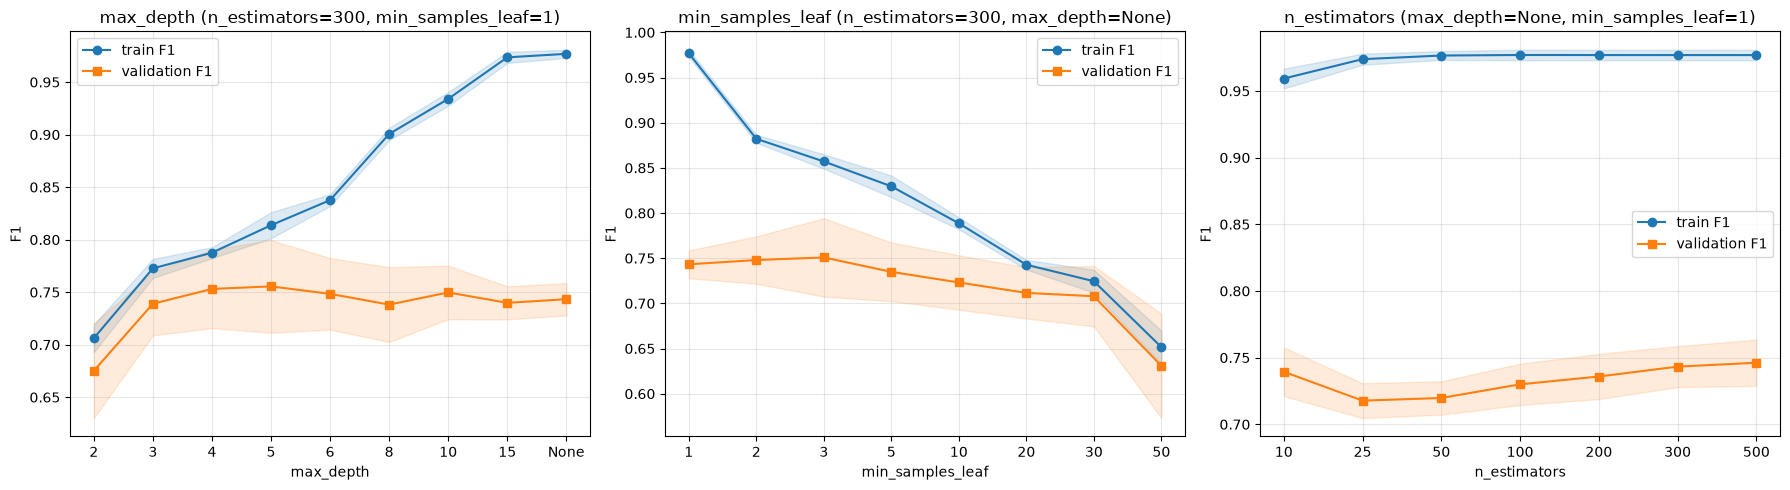

In [32]:
import matplotlib.pyplot as plt

def plot_sweep(ax, df_sweep, param_name, title):
    x = np.arange(len(df_sweep))
    ax.plot(x, df_sweep['train_mean'], marker='o', label='train F1', color='#1f77b4')
    ax.fill_between(x,
                    df_sweep['train_mean'] - df_sweep['train_std'],
                    df_sweep['train_mean'] + df_sweep['train_std'],
                    alpha=0.15, color='#1f77b4')
    ax.plot(x, df_sweep['val_mean'], marker='s', label='validation F1', color='#ff7f0e')
    ax.fill_between(x,
                    df_sweep['val_mean'] - df_sweep['val_std'],
                    df_sweep['val_mean'] + df_sweep['val_std'],
                    alpha=0.15, color='#ff7f0e')
    ax.set_xticks(x)
    ax.set_xticklabels(df_sweep['value'].astype(str))
    ax.set_xlabel(param_name)
    ax.set_ylabel('F1')
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_sweep(axes[0], sweep_max_depth, 'max_depth',
           'max_depth (n_estimators=300, min_samples_leaf=1)')
plot_sweep(axes[1], sweep_min_leaf, 'min_samples_leaf',
           'min_samples_leaf (n_estimators=300, max_depth=None)')
plot_sweep(axes[2], sweep_n_est, 'n_estimators',
           'n_estimators (max_depth=None, min_samples_leaf=1)')
plt.tight_layout()
plt.show()

По графику max_depth видна ожидаемая картина. При глубине 2 validation около 0.67 при train 0.71 - явное недообучение из-за слишком простых деревьев. При глубине 4-6 validation растет до 0.75, и это зона разумной сложности. Начиная с глубины 8, train F1 уходит к 0.9+, а validation стабилизируется на 0.74-0.75, разрыв между кривыми резко растет - это переобучение.

Кривая min_samples_leaf работает как зеркало. При значениях 1-2 train близок к 1.0 при validation около 0.75 - сильное переобучение. Лучший validation достигается при значении 3 (около 0.75), после чего он начинает плавно снижаться. При увеличении до 30-50 обе кривые падают, validation доходит до 0.63 - это зона недообучения.

Кривая n_estimators показывает, что при малом числе деревьев (10-50) validation проседает до 0.72 с заметным разбросом, но с ростом до 200-500 постепенно повышается до 0.75. Увеличение деревьев не переобучает модель, а только снижает дисперсию ансамбля.

Результаты графиков в целом согласуются с Grid и Random Search.

In [33]:
test_f1_baseline = f1_score(y_test, baseline_pipe.predict(X_test))
test_f1_grid = f1_score(y_test, grid_search.best_estimator_.predict(X_test))
test_f1_random = f1_score(y_test, random_search.best_estimator_.predict(X_test))

comparison_df = pd.DataFrame([
    {
        'Модель': 'Baseline',
        'Параметры': 'n_estimators=200, остальные по умолчанию',
        'CV F1 (mean)': fold_scores.mean(),
        'Test F1': test_f1_baseline
    },
    {
        'Модель': 'Grid Search',
        'Параметры': str({k.replace('model__', ''): v for k, v in grid_search.best_params_.items()}),
        'CV F1 (mean)': best_row['mean_test_score'],
        'Test F1': test_f1_grid
    },
    {
        'Модель': 'Random Search',
        'Параметры': str({k.replace('model__', ''): v for k, v in random_search.best_params_.items()}),
        'CV F1 (mean)': best_row_rs['mean_test_score'],
        'Test F1': test_f1_random
    }
])

print('Сравнение моделей (CV vs Test):')
print(comparison_df.round(4).to_string(index=False))

Сравнение моделей (CV vs Test):
       Модель                                                       Параметры  CV F1 (mean)  Test F1
     Baseline                        n_estimators=200, остальные по умолчанию        0.7359   0.7576
  Grid Search    {'max_depth': 4, 'min_samples_leaf': 1, 'n_estimators': 300}        0.7531   0.6780
Random Search {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 388}        0.7587   0.7200


По таблице видно, что оптимизация гиперпараметров улучшила качество на кросс-валидации: у модифицированных моделей CV F1 вырос в сравнении с baseline. Random Search нашёл лучшую комбинацию, чем полный перебор, за счёт того, что попал в область min_samples_leaf=3 и n_estimators=388, которых не было в сетке Grid.

Однако на тестовой выборке картина обратная: baseline показал самый высокий Test F1 (0.7576), Random Search оказался посередине (0.7200), а Grid Search - самым низким (0.6780). Улучшение на кросс-валидации не только не перенеслось на test, но и привело к заметному падению качества по сравнению с исходной моделью. Это классический пример того, что оптимизация гиперпараметров не гарантирует прирост на новых данных.

Одной из причин расхождения может являться то, что кросс-валидация оценивает модель на 5 фолдах по ~142 объекта, а тест - это один фиксированный набор из 179 объектов. На таком малом объёме данных разница между лучшей и средней комбинацией на CV может оказаться шумом. Grid Search подобрал max_depth=4, что вероятно сделало модель слишком простой для тестовой выборки (недообучение), а Random Search с max_depth=None и min_samples_leaf=3 оказался ближе к дефолтному поведению, но тоже не превзошёл baseline. Исходный baseline с большим числом деревьев (200) и неограниченной глубиной, по-видимому, лучше уловил закономерности именно этого тестового набора.

Важно, что это не нарушает честность эксперимента: все решения о параметрах принимались только по train и кросс-валидации, а тест открывался один раз в самом конце. Полученная оценка честная, и она показывает реальный риск переобучения на фолды кросс-валидации при небольшом размере выборки.

In [34]:
baseline_folds = fold_scores
grid_best_idx = grid_search.best_index_
random_best_idx = random_search.best_index_

grid_folds = [grid_results.loc[grid_best_idx, f'split{i}_test_score'] for i in range(N_SPLITS)]
random_folds = [random_results.loc[random_best_idx, f'split{i}_test_score'] for i in range(N_SPLITS)]

stability_df = pd.DataFrame({
    'Fold': [f'fold {i+1}' for i in range(N_SPLITS)],
    'Baseline': baseline_folds,
    'Grid Search': grid_folds,
    'Random Search': random_folds
})

print('F1 по фолдам для лучших моделей:')
print(stability_df.round(4).to_string(index=False))

print('\nСреднее и стандартное отклонение:')
print(f'Baseline:      mean={np.mean(baseline_folds):.4f}, std={np.std(baseline_folds):.4f}')
print(f'Grid Search:   mean={np.mean(grid_folds):.4f}, std={np.std(grid_folds):.4f}')
print(f'Random Search: mean={np.mean(random_folds):.4f}, std={np.std(random_folds):.4f}')

F1 по фолдам для лучших моделей:
  Fold  Baseline  Grid Search  Random Search
fold 1    0.7455       0.7921         0.7736
fold 2    0.7339       0.7312         0.7048
fold 3    0.7593       0.8000         0.8163
fold 4    0.7080       0.7400         0.7358
fold 5    0.7327       0.7021         0.7629

Среднее и стандартное отклонение:
Baseline:      mean=0.7359, std=0.0169
Grid Search:   mean=0.7531, std=0.0373
Random Search: mean=0.7587, std=0.0374


По результатам фолдов видно, что Baseline оказался самой стабильной моделью: разброс std=0.0169, значения держатся в узком диапазоне от 0.7080 до 0.7593. У Grid и Random Search среднее качество выше (0.7531 и 0.7587), но разброс почти в два раза больше (std около 0.037). У них есть фолды с очень высоким F1 (0.7921 и 0.8163) и фолды с сильным провалом (0.7021 и 0.7048).

Две модели с одинаковым средним могут различаться по устойчивости из-за чувствительности к составу данных. Baseline с неограниченной глубиной и 200 деревьями усредняет предсказания более плавно и меньше зависит от того, какие именно объекты попали в конкретный фолд. Тюнингованные модели сильнее подстраиваются под обучающую часть фолда, поэтому на одних разбиениях они показывают отличный результат, а на других — заметно проседают.

Это объясняет результаты финального теста: высокое среднее CV у Grid и Random было достигнуто за счет нескольких очень удачных фолдов, а не за счет стабильного превосходства. На новой тестовой выборке именно более устойчивый Baseline показал лучшее качество (Test F1 = 0.7576), тогда как тюнингованные модели не смогли обобщить свой высокий CV-score.